# PROG8431 – Problem Analysis Workshop B
## K-Means Clustering: Ontario Property Dataset

## Group 5

### Team Members

| Name | Student ID |
|------|------------|
| Asangika Hettiarachchi | 7461502 |
| Juan Antonio Sainz Galvez | 9072844 |
| Ved Vishal Patel | 9111628 |

**Dataset:** `data/properties.csv` – [Ontario Residential Property Data (Kaggle)](https://www.kaggle.com/datasets/mnabaee/ontarioproperties), the same source used in Group Assignment 1 and Workshop A.

This notebook follows the clustering demonstration from class: data cleaning, selection of two clustering variables, z-score standardization, the K-Means assignment/update procedure, candidate K values from 2–10, the elbow method plus the silhouette score, cluster sizes, centroids, within-cluster sum of squares, visualization, and cluster summaries.

## Why clustering for our term project

Our term project compares the housing market of **Kitchener-Waterloo / Cambridge** with the **Toronto area**. So far we compared groups that *we* defined (for example Downtown Toronto vs. Mississauga in Workshop A). Clustering lets the **data define the groups**: K-Means finds natural market segments based on price and distance to Toronto, without us drawing boundaries by hand.

This helps us answer:
- Which market segments exist in Ontario (e.g., expensive homes close to Toronto vs. affordable homes far from it)?
- Where do KW/Cambridge properties fall – do they behave like the Toronto-area market or like the more distant, cheaper markets?
- How large is each segment, and how different are their typical prices?

## 1. Setup and load data

In [2]:
# Setup: run `pip install -r requirements.txt` inside the project .venv before this cell.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

properties = pd.read_csv("./data/properties.csv")
print("Dataset shape:", properties.shape)
display(properties.head())

Dataset shape: (25351, 6)


,Unnamed: 0,Address,AreaName,Price ($),lat,lng
0,0,"86 Waterford Dr Toronto, ON",Richview,999888,43.679882,-79.544266
1,1,"#80 - 100 BEDDOE DR Hamilton, ON",Chedoke Park B,399900,43.250000,-79.904396
2,2,"213 Bowman Street Hamilton, ON",Ainslie Wood East,479000,43.251690,-79.919357
3,3,"102 NEIL Avenue Hamilton, ON",Greenford,285900,43.227161,-79.767403
4,6,"#1409 - 230 King St Toronto, ON",Downtown,362000,43.651478,-79.368118


## 2. Inspect the data

In [3]:
print(properties.info())
display(properties.describe(include="all").T)
display(properties.isna().sum().rename("Missing values").to_frame())
print("Duplicate rows:", properties.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 25351 entries, 0 to 25350
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  25351 non-null  int64  
 1   Address     25351 non-null  str    
 2   AreaName    24868 non-null  str    
 3   Price ($)   25351 non-null  int64  
 4   lat         25351 non-null  float64
 5   lng         25351 non-null  float64
dtypes: float64(2), int64(2), str(2)
memory usage: 1.2 MB
None


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,25351.0,NaN,NaN,NaN,42878.517613,31456.247046,0.0,19940.0,34037.0,61501.5,124929.0
Address,25351,23594,"223 Erb Street Waterloo, ON",16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AreaName,24868,1119,Downtown,830,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price ($),25351.0,NaN,NaN,NaN,564543.765137,847596.167337,0.0,219900.0,371900.0,619900.0,32500000.0
lat,25351.0,NaN,NaN,NaN,37.326614,82.858347,-999.0,43.401087,43.715977,44.466711,53.851017
lng,25351.0,NaN,NaN,NaN,-85.218379,73.093572,-999.0,-80.308159,-79.503342,-79.107326,1.074519


,Missing values
Unnamed: 0,0
Address,0
AreaName,483
Price ($),0
lat,0
lng,0


Duplicate rows: 0


## 3. Clean the data

The inspection shows three data-quality problems that would distort the clusters:

1. **Missing coordinates coded as -999.** Some rows have `lat = -999` and `lng = -999`. This is a missing-value code, not a real location; left in, these rows form their own "cluster" that does not exist on the map.
2. **Coordinates outside Ontario.** A few rows have impossible coordinates (e.g., positive longitude). We keep only points inside Ontario's bounding box (latitude 41.6–57.0, longitude -95.2 to -74.3). This removes impossible values, not real Ontario regions.
3. **Very low prices.** Rows priced under **$10,000** (some at $1 or $2,000) are most likely monthly rents or data-entry errors, not sale prices.

We also drop the exported index column (`Unnamed: 0`).

In [4]:
MIN_PRICE = 10_000
ONTARIO_LAT = (41.6, 57.0)
ONTARIO_LNG = (-95.2, -74.3)

data = properties.drop(columns=["Unnamed: 0"], errors="ignore").copy()
for col in ["Price ($)", "lat", "lng"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data = data.dropna(subset=["Price ($)", "lat", "lng"])

missing_coords = (data["lat"] == -999) | (data["lng"] == -999)
outside_ontario = ~missing_coords & ~(
    data["lat"].between(*ONTARIO_LAT) & data["lng"].between(*ONTARIO_LNG)
)
low_price = ~missing_coords & ~outside_ontario & (data["Price ($)"] < MIN_PRICE)

cleaning_summary = pd.DataFrame({
    "Rule": ["Coordinates = -999 (missing)", "Coordinates outside Ontario", f"Price below ${MIN_PRICE:,}"],
    "Rows removed": [missing_coords.sum(), outside_ontario.sum(), low_price.sum()],
})
display(cleaning_summary)

data = data[~(missing_coords | outside_ontario | low_price)].copy()
print(f"Rows before cleaning: {len(properties):,}")
print(f"Rows used for clustering: {len(data):,}")

,Rule,Rows removed
0,Coordinates = -999 (missing),161
1,Coordinates outside Ontario,24
2,"Price below $10,000",912


Rows before cleaning: 25,351
Rows used for clustering: 24,254


## 4. Choose two clustering variables

The instructions ask for **two variables** to define the clusters. We use:

1. **`Price ($)`** – the variable our whole term project is about (housing affordability).
2. **`Distance to Toronto (km)`** – the straight-line distance from each property to downtown Toronto (Toronto City Hall, 43.6532, -79.3832), computed from `lat` and `lng` with the haversine formula.

**Why distance instead of raw latitude and longitude?** Our research question compares KW/Cambridge with the Toronto area, so what matters is *how far from Toronto* a property is. Distance condenses the two coordinates into one meaningful number, which keeps us at two variables and makes every cluster easy to interpret ("expensive and close" vs. "cheap and far").

In [5]:
TORONTO_LAT, TORONTO_LNG = 43.6532, -79.3832
EARTH_RADIUS_KM = 6371


def distance_to_toronto_km(lat, lng):
    """Return the great-circle (haversine) distance in km from each point to downtown Toronto."""
    lat1, lat2 = np.radians(lat), np.radians(TORONTO_LAT)
    delta_lat = lat2 - lat1
    delta_lng = np.radians(TORONTO_LNG - lng)
    a = np.sin(delta_lat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lng / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))


data["Distance to Toronto (km)"] = distance_to_toronto_km(data["lat"], data["lng"])
features = ["Price ($)", "Distance to Toronto (km)"]
display(data[features].describe().round(1))

,Price ($),Distance to Toronto (km)
count,24254.0,24254.0
mean,586702.8,141.2
std,858633.8,136.7
min,10000.0,0.0
25%,239900.0,23.6
50%,388888.0,91.6
75%,630000.0,241.4
max,32500000.0,1357.5


## 5. Explore the two variables

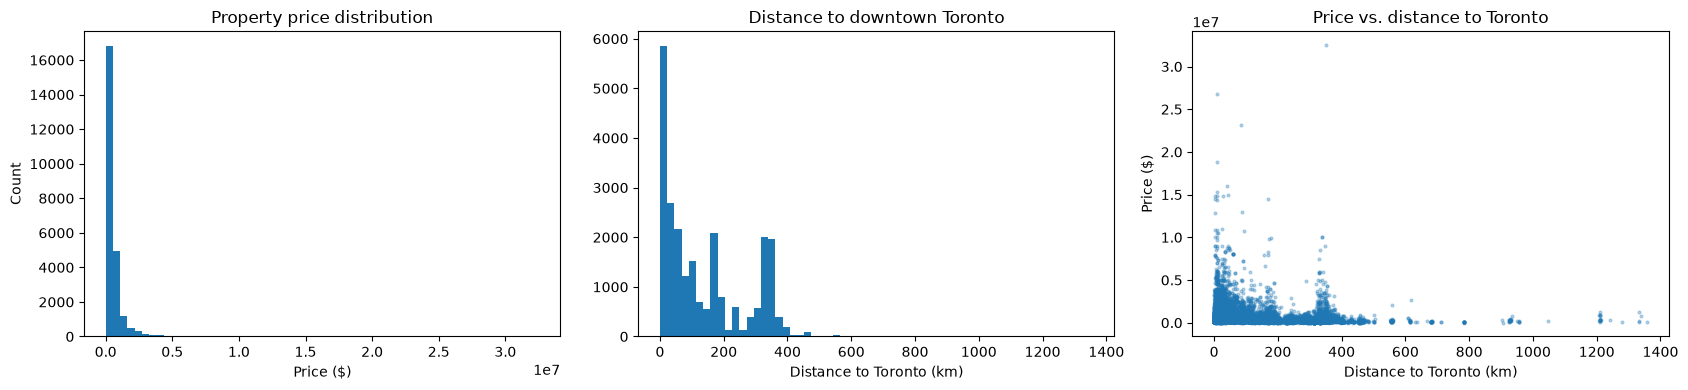

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(data["Price ($)"], bins=60)
axes[0].set_title("Property price distribution")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Count")
axes[1].hist(data["Distance to Toronto (km)"], bins=60)
axes[1].set_title("Distance to downtown Toronto")
axes[1].set_xlabel("Distance to Toronto (km)")
axes[2].scatter(data["Distance to Toronto (km)"], data["Price ($)"], s=4, alpha=0.3)
axes[2].set_title("Price vs. distance to Toronto")
axes[2].set_xlabel("Distance to Toronto (km)")
axes[2].set_ylabel("Price ($)")
plt.tight_layout()
plt.show()

Both variables are strongly right-skewed: most homes cost under $1M and sit within ~250 km of Toronto, with a long tail of luxury homes and distant properties. The two variables are also on very different scales (hundreds of thousands of dollars vs. hundreds of kilometres).

## 6. Standardize the variables

\[
z_i = \frac{x_i-\bar{x}}{\sigma}
\]

K-Means uses Euclidean distance, so without scaling, `Price ($)` (values in the hundreds of thousands) would completely dominate `Distance to Toronto (km)` (values in the hundreds) and the clusters would be based on price alone.

We use **z-score standardization** (one of the two methods from class) rather than min-max scaling: min-max squeezes every value into 0–1 using the single minimum and maximum, so one $32.5M mansion would compress almost all other prices near 0. Z-scores use the mean and standard deviation, so the bulk of the data keeps its spread. After standardization both variables have mean ≈ 0 and standard deviation ≈ 1.

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[features])
scaled_data = pd.DataFrame(X_scaled, columns=features, index=data.index)
display(scaled_data.describe().round(3))

,Price ($),Distance to Toronto (km)
count,24254.000,24254.000
mean,-0.000,0.000
std,1.000,1.000
min,-0.672,-1.033
25%,-0.404,-0.861
50%,-0.230,-0.363
75%,0.050,0.733
max,37.168,8.899


## 7. K-Means procedure

For a chosen K:
1. Initialize K centroids.
2. Assign each observation to its nearest centroid using Euclidean distance.
3. Recalculate each centroid as the mean of its assigned observations.
4. Repeat assignment and recalculation until the solution stabilizes.

The 2D Euclidean distance is:

\[
d=\sqrt{(x_2-x_1)^2+(y_2-y_1)^2}
\]

## 8. Choose K: elbow method and silhouette score

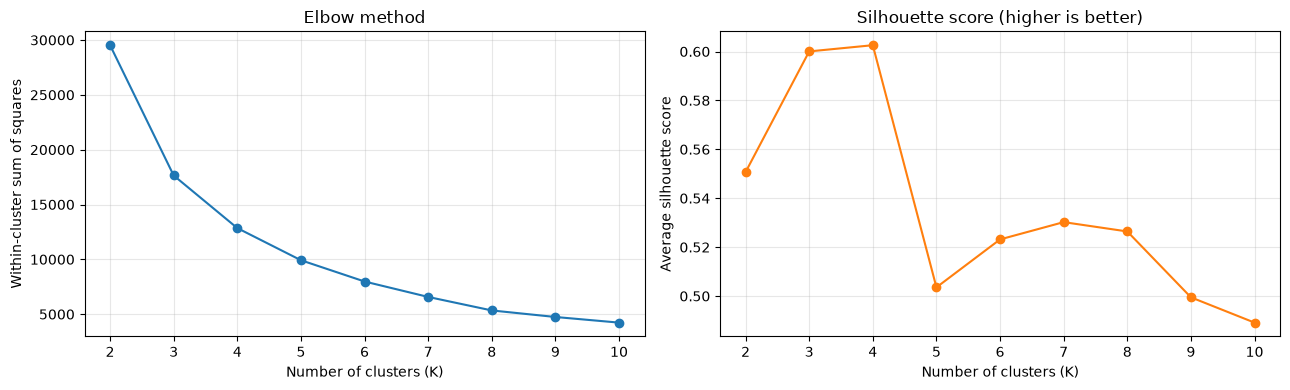

,K,Within-cluster SS,Silhouette score
0,2,29526.5,0.551
1,3,17645.7,0.600
2,4,12848.7,0.603
3,5,9918.8,0.504
4,6,7978.2,0.523
5,7,6571.1,0.530
6,8,5339.7,0.526
7,9,4743.1,0.499
8,10,4229.1,0.489


In [8]:
k_values = list(range(2, 11))
inertias = []
silhouettes = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels, sample_size=8000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Within-cluster sum of squares")
axes[0].set_xticks(k_values)
axes[0].grid(True, alpha=0.3)
axes[1].plot(k_values, silhouettes, marker="o", color="tab:orange")
axes[1].set_title("Silhouette score (higher is better)")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Average silhouette score")
axes[1].set_xticks(k_values)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"K": k_values, "Within-cluster SS": np.round(inertias, 1), "Silhouette score": np.round(silhouettes, 3)}))

**Choosing K = 3.**
- **Elbow:** the within-cluster sum of squares drops sharply from K = 2 to K = 3 and then decreases more gradually – the bend of the elbow is at K = 3.
- **Silhouette:** K = 3 has one of the highest silhouette scores (about 0.60). K = 4 scores about the same, but its extra cluster only holds about 80 ultra-luxury homes, which adds little insight.
- **Interpretability:** K = 3 gives three segments that are large enough to compare and easy to explain in our term project.

In [9]:
K_FINAL = 3

final_model = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
data["Cluster"] = final_model.fit_predict(X_scaled)

## 9. Evaluate sizes, centroids, and within-cluster sum of squares

In [10]:
cluster_sizes = data["Cluster"].value_counts().sort_index()
print("Cluster sizes:")
display(cluster_sizes.rename("Number of properties").to_frame())

centroids_scaled = pd.DataFrame(
    final_model.cluster_centers_,
    columns=features,
    index=[f"Cluster {i}" for i in range(K_FINAL)],
)
centroids_original = pd.DataFrame(
    scaler.inverse_transform(final_model.cluster_centers_),
    columns=features,
    index=centroids_scaled.index,
)
print("Centroids (standardized units):")
display(centroids_scaled.round(3))
print("Centroids (original units):")
display(centroids_original.round(0))

print("Total within-cluster sum of squares:", round(final_model.inertia_, 2))

Cluster sizes:


,Number of properties
Cluster,
0,16794
1,6777
2,683


Centroids (standardized units):


,Price ($),Distance to Toronto (km)
Cluster 0,-0.056,-0.536
Cluster 1,-0.286,1.389
Cluster 2,4.210,-0.608


Centroids (original units):


,Price ($),Distance to Toronto (km)
Cluster 0,538952.0,68.0
Cluster 1,340747.0,331.0
Cluster 2,4201296.0,58.0


Total within-cluster sum of squares: 17645.69


## 10. Visualize clusters

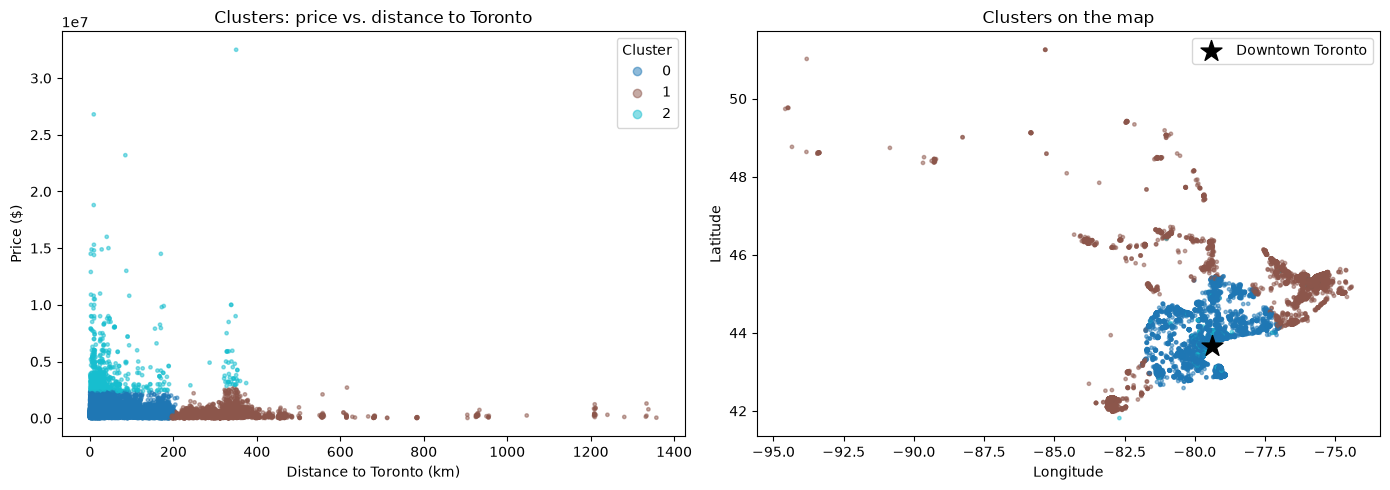

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter = axes[0].scatter(
    data["Distance to Toronto (km)"], data["Price ($)"],
    c=data["Cluster"], cmap="tab10", s=6, alpha=0.5,
)
axes[0].set_title("Clusters: price vs. distance to Toronto")
axes[0].set_xlabel("Distance to Toronto (km)")
axes[0].set_ylabel("Price ($)")
axes[0].legend(*scatter.legend_elements(), title="Cluster")

axes[1].scatter(data["lng"], data["lat"], c=data["Cluster"], cmap="tab10", s=6, alpha=0.5)
axes[1].scatter(TORONTO_LNG, TORONTO_LAT, marker="*", s=250, c="black", label="Downtown Toronto")
axes[1].set_title("Clusters on the map")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].legend()
plt.tight_layout()
plt.show()

## 11. Summarize clusters

In [12]:
profile = data.groupby("Cluster").agg(
    Count=("Price ($)", "size"),
    Mean_Price=("Price ($)", "mean"),
    Median_Price=("Price ($)", "median"),
    Min_Price=("Price ($)", "min"),
    Max_Price=("Price ($)", "max"),
    Median_Distance_km=("Distance to Toronto (km)", "median"),
).round(0)
profile["Share_%"] = (profile["Count"] / profile["Count"].sum() * 100).round(1)
display(profile)

,Count,Mean_Price,Median_Price,Min_Price,Max_Price,Median_Distance_km,Share_%
Cluster,,,,,,,
0,16794,538952.0,420000.0,10000,2358888,50.0,69.2
1,6777,340747.0,280000.0,10000,2700000,333.0,27.9
2,683,4201296.0,3300000.0,2375000,32500000,28.0,2.8


## 12. Cluster Names and Insights

**Section owner:** Ved Vishal Patel (Student ID: 9111628)

### 12.1 Giving meaningful names to the clusters

After running K-Means with **K = 3**, we looked at the cluster summary in Section 11. We used the **median property price**, **median distance from downtown Toronto**, and **number of properties** to describe each group. The names below are our interpretations of the results; K-Means itself only assigns the numerical labels 0, 1, and 2.

| Cluster | Descriptive name | Properties | Share of data | Median price | Median distance to Toronto |
|:--|:--|--:|--:|--:|--:|
| **0** | Mainstream, Closer-to-Toronto Properties | 16,794 | 69.2% | $420,000 | 50 km |
| **1** | Lower-Priced, Farther-Away Properties | 6,777 | 27.9% | $280,000 | 333 km |
| **2** | High-Priced, Closer-to-Toronto Properties | 683 | 2.8% | $3,300,000 | 28 km |

*Note:* The distances are approximate **straight-line distances** from downtown Toronto, not driving distances. Percentages are rounded, so they may not add to exactly 100%.

### 12.2 What each cluster tells us

**Cluster 0 — Mainstream, Closer-to-Toronto Properties**

This is the largest group, with **16,794 properties (69.2%)**. Its median price is **$420,000**, and its median distance from Toronto is **50 km**. We chose this name because these properties are generally closer to Toronto than Cluster 1 and are much less expensive than the high-priced properties in Cluster 2. This group represents the main part of our cleaned dataset.

**Cluster 1 — Lower-Priced, Farther-Away Properties**

This group contains **6,777 properties (27.9%)**. Its median price is **$280,000**, and its median distance from Toronto is **333 km**. We chose this name because it has the **lowest median price** and the **greatest median distance** of the three clusters. In our dataset, this group suggests that many farther-away properties fall into a lower-priced segment.

**Cluster 2 — High-Priced, Closer-to-Toronto Properties**

This is the smallest group, with **683 properties (2.8%)**. Its median price is **$3,300,000**, and its median distance from Toronto is **28 km**. We chose this name because its typical property price is much higher than in the other groups, while its median distance is relatively short. It shows that K-Means can separate a small, very expensive property segment from the larger nearby market.

### 12.3 Main insights from the clustering

1. **The property market is not one uniform group.** The model separates the cleaned data into a large mainstream segment, a lower-priced distant segment, and a small high-priced segment.
2. **Distance and price help distinguish these groups.** Cluster 1 has both the greatest median distance and the lowest median price. However, this is an **association in this dataset**, not proof that distance causes a lower price.
3. **Properties closer to Toronto do not all have similar prices.** Clusters 0 and 2 both have relatively short median distances, but their median prices are very different (**$420,000 versus $3,300,000**).
4. **Cluster sizes are quite different.** Cluster 0 accounts for most properties, while Cluster 2 accounts for only **2.8%**. That is useful context when comparing the groups; the smallest cluster should not be treated as typical of the overall market.

### 12.4 How this helps our term project

Our term project compares the housing market in **Kitchener-Waterloo/Cambridge** with the **Toronto area**. Previously, we could compare locations that we selected ourselves. With clustering, we can also see which **price-and-distance segments** appear naturally in the dataset.

For example, we can use these groups to ask whether properties in Kitchener-Waterloo/Cambridge are mostly part of the mainstream segment or are distributed across several segments. **We have not calculated the cluster counts separately for each region in this notebook**, so we should not claim a regional result yet. That would be a useful next analysis.

In [13]:
cities = ["Toronto", "Kitchener", "Waterloo", "Cambridge"]
rows = []
for city in cities:
    subset = data[data["Address"].str.contains(f"{city}, ON", case=False, na=False)]
    counts = subset["Cluster"].value_counts().reindex(range(K_FINAL), fill_value=0)
    rows.append({"City": city, "Listings": len(subset), **{f"Cluster {k}": counts[k] for k in range(K_FINAL)}, "Median price": subset["Price ($)"].median()})
display(pd.DataFrame(rows))

,City,Listings,Cluster 0,Cluster 1,Cluster 2,Median price
0,Toronto,4982,4727,0,255,483883.0
1,Kitchener,525,518,0,7,369900.0
2,Waterloo,500,497,0,3,399900.0
3,Cambridge,117,117,0,0,389900.0


When I ran it, almost all Kitchener (518 of 525), Waterloo (497 of 500) and Cambridge (117 of 117) listings fall in Cluster 0, the same mainstream segment as most of Toronto (4,727 listings), while Toronto also has 255 listings in the high-priced Cluster 2.

### 12.5 Final takeaway

**K-Means helped us organize the property listings into three understandable market segments using price and distance to Toronto.** The main lesson is that both the property's location relative to Toronto and its price matter when describing the market. These groups give us a clearer starting point for comparing housing patterns in our term project, while remembering that clustering describes patterns rather than proving their causes.